# Подготовительные моменты

Подключение необходимых библиотек.

In [1]:
import bs4
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
import requests
from collections import Counter
from itertools import chain
from nltk.corpus import stopwords
from nltk.tokenize import WordPunctTokenizer
from pymorphy3 import MorphAnalyzer
from wordcloud import WordCloud

nltk.download("stopwords")
sns.set_theme()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sosno\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Создание `DataFrame` со следующими столбцами:
- `name` - название ресторана, о котором оставлен отзыв;
- `address` - адрес этого ресторана;
- `url` - ссылка на страницу с отзывами об этом ресторане;
- `datetime` - дата и время, когда был оставлен отзыв;
- `rating` - оставленная пользователем оценка от 1 до 5;
- `text` - текст отзыва.

Далее заполним его отзывами о ресторанах и кафе в Саратове.

In [ ]:
reviews = pd.DataFrame(columns=["name", "address", "url", "datetime", "rating", "text"])
reviews = reviews.astype({"datetime": "datetime64[ns]", "rating": "int64"})

# Парсинг отзывов о ресторанах и кафе

Функция парсинга страницы со списком ресторанов на сайте Yell.ru. Загружается страница сайта и преобразуется в объект библиотеки `BeautifulSoup4`. С помощью её функции в html-коде страницы ищется карточка каждого ресторана и передаётся в следующую функцию, результат которой добавляется в созданный временный `DataFrame`. Он возвращается описываемой функцией, когда будут получены отзывы о всех ресторанах на данной странице.

In [ ]:
def get_yell_reviews_from_page(page_index: int) -> pd.DataFrame:
    url = f"https://www.yell.ru/saratov/top/restorany/?page={page_index}"
    response = requests.get(url)
    soup = bs4.BeautifulSoup(response.text, "html.parser")
    reviews = pd.DataFrame(columns=["name", "address", "url", "datetime", "rating", "text"])
    reviews = reviews.astype({"rating": "int64", "datetime": "datetime64[ns]"})
    for restaurant in soup.find_all("div", class_="companies__item-content"):
        reviews = pd.concat(
            [reviews, get_yell_reviews_about_restaurant(restaurant)], ignore_index=True
        )
    return reviews

Функция парсинга страницы с отзывами о конкретном ресторане на сайте Yell.ru. Из полученной ранее карточки ресторана извлекаются его название, адрес и ссылка на страницу с информацией о нём. Затем эта страница загружается и аналогично преобразуется в объект библиотеки `BeautifulSoup4`. Далее с помощью её функций ищутся все карточки с отзывами, из которых извлекаются время, оценка и текст. После этого создаётся запись об отзыве и сохраняется во временный список. Когда все отзывы со страницы получены, этот список преобразуется в `DataFrame` и возвращается описываемой функцией.

In [ ]:
def get_yell_reviews_about_restaurant(restaurant: bs4.element.Tag) -> pd.DataFrame:
    name = restaurant.a.text.strip()
    address = restaurant.find_next("div", class_="companies__item-address").text.strip()
    url = "https://www.yell.ru" + restaurant.a.get("href")
    response = requests.get(url)
    soup = bs4.BeautifulSoup(response.text, "html.parser")
    data = []
    for review in soup.find_all("div", class_="reviews__item-content"):
        datetime = review.find_next("span", class_="reviews__item-added").get("content").split("+")[0]
        rating = review.find_next("div", class_="rating rating_size_m").text
        text = review.find_next("div", class_="reviews__item-text").text
        data.append({
            "name": name, "address": address, "url": url,
            "datetime": datetime, "rating": rating, "text": text
        })
    if not data:
        return pd.DataFrame()
    reviews = pd.DataFrame(data)
    reviews.datetime = pd.to_datetime(reviews.datetime)
    reviews.rating = reviews.rating.astype(int)
    return reviews

Функция парсинга страницы со списком ресторанов, выполняющая аналогичные действия для сайта Flamp.ru.

In [ ]:
def get_flamp_reviews_from_page(page_index: int) -> pd.DataFrame:
    url = f"https://saratov.flamp.ru/metarubric/eda?page={page_index}"
    response = requests.get(url)
    soup = bs4.BeautifulSoup(response.text, "html.parser")
    reviews = pd.DataFrame(columns=["name", "address", "url", "rating", "datetime", "text"])
    reviews = reviews.astype({"rating": "int64", "datetime": "datetime64[ns]"})
    for restaurant in soup.find_all("div", class_="card__info"):
        reviews = pd.concat(
            [reviews, get_flamp_reviews_about_restaurant(restaurant)], ignore_index=True
        )
    return reviews

Функция парсинга страницы с отзывами о конкретном ресторане, выполняющая аналогичные действия для сайта Flamp.ru.

In [ ]:
def get_flamp_reviews_about_restaurant(restaurant: bs4.element.Tag) -> pd.DataFrame:
    name = restaurant.a.text.strip()
    address = (restaurant.find_next("ul", class_="card__footer-list")
               .get_text(";", strip=True).split(";")[1].split("—")[0].strip())
    url = "https:" + restaurant.a.get("href")
    response = requests.get(url)
    soup = bs4.BeautifulSoup(response.text, "html.parser")
    data = []
    for review in soup.find_all("article", class_="ugc-item"):
        datetime = review.find_next("cat-brand-ugc-date").get("date").split("+")[0]
        rating = review.find_next("cat-brand-review-estimation").get("estimation")
        text = review.find_next(
            "div", class_="t-text t-rich-text ugc-item__text ugc-item__text--full js-ugc-item-text-full"
        ).text.strip()
        data.append({
            "name": name, "address": address, "url": url,
            "datetime": datetime, "rating": rating, "text": text
        })
    if not data:
        return pd.DataFrame()
    reviews = pd.DataFrame(data)
    reviews.datetime = pd.to_datetime(reviews.datetime)
    reviews.rating = reviews.rating.astype(int)
    return reviews

Скачивание отзывов о ресторанах с первых десяти страниц каждого сайта и сохранение в csv-файл.

In [ ]:
for i in range(1, 11):
    reviews = pd.concat([reviews, get_yell_reviews_from_page(i)], ignore_index=True)
    reviews = pd.concat([reviews, get_flamp_reviews_from_page(i)], ignore_index=True)
reviews.to_csv("reviews.csv", index=False)

# Анализ собранных данных

Восстановление `DataFrame` с отзывами из сохранённого csv-файла.

In [2]:
reviews = pd.read_csv("reviews.csv")
reviews

,name,address,url,datetime,rating,text
0,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-08-29 12:49:44,5,"Все понравилось орегенально,персоналу огромное..."
1,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-08-22 11:59:40,5,Всё горячее уха наваристая шашлык свиной сочны...
2,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-06-18 10:21:51,5,Приятное место с разнообразным меню. Всегда на...
3,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-06-04 13:27:13,5,Отличное кафе! Гостям понравилось. Обслуживани...
4,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-05-28 11:52:40,5,Отмечал тут свое день рождение в узкой компани...
...,...,...,...,...,...,...
1224,Duran,"Саратов, Рабочая улица, 145а",https://saratov.flamp.ru/firm/duran_restoran-7...,2020-08-25 22:30:41,5,Одно из лучших мест в Саратове!!! Очень вкусна...
1225,Панорама,"Саратов, Аэропорт, 5а",https://saratov.flamp.ru/firm/panorama_restora...,2016-07-01 21:44:17,5,Вел в этом ресторане свадьбу. Довольно приличн...
1226,Столовая №1,"Саратов, им. Петра Столыпина проспект, 54",https://saratov.flamp.ru/firm/stolovaya_1_kafe...,2021-04-07 12:46:40,5,Заезжали в будний день почти перед закрытием. ...
1227,Старый Патефон,"Саратов, Московская улица, 48",https://saratov.flamp.ru/firm/staryjj_patefon_...,2017-03-18 16:07:49,5,Отличное место! Один из любимейших караоке зал...


Просмотр количества пропусков в данных и типов столбцов.

In [ ]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1229 entries, 0 to 1228
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   name      1229 non-null   object
 1   address   1229 non-null   object
 2   url       1229 non-null   object
 3   datetime  1229 non-null   object
 4   rating    1229 non-null   int64 
 5   text      1229 non-null   object
dtypes: int64(1), object(5)
memory usage: 57.7+ KB


Приведение столбца `datetime` к соответствующему типу и просмотр основных числовых характеристик количественных признаков, т. е. даты и оценки. Видно, что отзывы достаточно равномерно распределены с 2010 по 2025 год. Также, минимальной оценкой является 0, а не 1 как ожидалось.

In [ ]:
reviews = reviews.astype({"datetime": "datetime64[ns]"})
reviews.describe()

,datetime,rating
count,1229,1229.000000
mean,2017-05-07 05:48:53.268511232,3.970708
min,2010-09-29 08:42:06,0.000000
25%,2015-02-19 18:45:10,3.000000
50%,2016-07-18 15:02:12,5.000000
75%,2019-01-21 06:20:05,5.000000
max,2025-06-26 12:34:11,5.000000
std,NaN,1.443548


Просмотр отзывов с оценкой 0. Оказывается, что их всего лишь два, поэтому их можно удалить.

In [ ]:
reviews[reviews.rating == 0]

,name,address,url,datetime,rating,text
64,Фудзи на Советской улице,"Россия, г Саратов, ул Советская, д 31",https://www.yell.ru/saratov/com/fudzi_5388017/,2013-04-25 22:30:53,0,"вкусно готовят,суши роллы делают быстро,уютное..."
876,Flash bar в Фрунзенском районе,"Россия, г Саратов, пр-кт им Кирова С.М., д 12",https://www.yell.ru/saratov/com/flash-bar_1017...,2013-04-25 15:33:29,0,Часто заходим сюда с друзьями. Место отличное ...


Удаление соответствующих отзывов и проверка распределения оценок. Средняя оценка равна 4, из чего можно сделать вывод, что большинству людей нравятся рестораны и кафе в Саратове.

In [ ]:
reviews.drop([64, 876], inplace=True)
reviews.reset_index(drop=True, inplace=True)
reviews.describe()

,datetime,rating
count,1227,1227.000000
mean,2017-05-09 15:25:00.183374080,3.977180
min,2010-09-29 08:42:06,1.000000
25%,2015-02-23 01:39:56,3.000000
50%,2016-07-21 23:00:21,5.000000
75%,2019-01-25 01:07:53.500000,5.000000
max,2025-06-26 12:34:11,5.000000
std,NaN,1.435782


Просмотр основных числовых характеристик категориальных признаков.

In [ ]:
reviews.describe(include="object")

,name,address,url,text
count,1227,1227,1227,1227
unique,264,267,286,1217
top,Кофе и шоколад,"Саратов, им. Зарубина В.С. улица, 167",https://saratov.flamp.ru/firm/rostic_s_restora...,"Очень комфортное атмосферное место, обслуживан..."
freq,25,18,5,3


Просмотр распределения отзывов по оценкам. Примерно половина отзывов имеют оценку 5, а самая редкая оценка — 2.

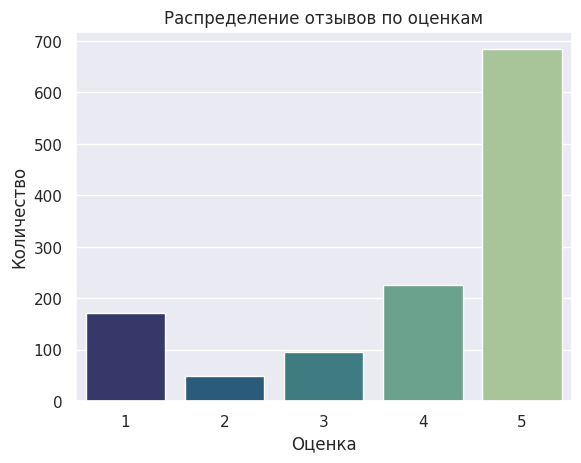

In [ ]:
sns.countplot(
    reviews, x="rating", hue="rating", palette="crest_r", legend=None
).set(
    title="Распределение отзывов по оценкам", xlabel="Оценка", ylabel="Количество"
);

Просмотр распределения отзывов по времени суток. Чаще всего посетители ресторанов и кафе оставляют отзывы около полудня и поздним вечером, а реже всего — в течение ночи.

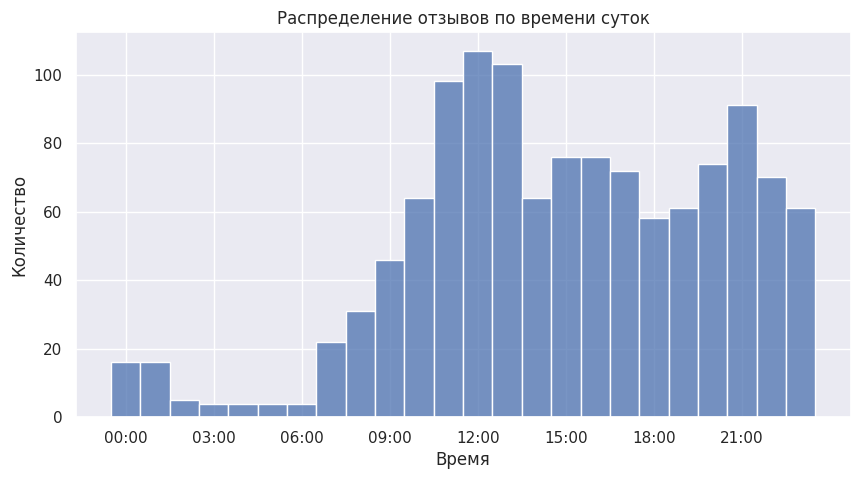

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(
    reviews, x=reviews.datetime.dt.hour, bins=24, discrete=True
).set(
    title="Распределение отзывов по времени суток", xlabel="Время", ylabel="Количество",
    xticks=range(0, 24, 3), xticklabels=[f"{hour:02d}:00" for hour in range(0, 24, 3)]
);

# Визуализация встречаемости слов в отзывах в зависимости от оценки

Функция нормализации текста отзыва. Сначала текст приводится к нижнему регистру и происходит его разделение на токены с помощью `WordPunctTokenizer` библиотеки `nltk`. Затем выбираются токены, которые целиком состоят из букв, т. е. являются словами, и приводятся к нормальной форме с помощью `MorphAnalyzer` библиотеки `pymorphy3`. Все буквы «ё» заменяются на «е», после чего остаются только те слова, которые не содержатся в списке стоп-слов русского языка библиотеки `nltk`. Этот список был дополнен словами, которые часто встречались в отзывах, независимо от оценки. Из нормализованных и отфильтрованных слов собирается строка и возвращается этой функцией.

In [ ]:
def normalize_review(review: str) -> str:
    tokenizer = WordPunctTokenizer()
    morph = MorphAnalyzer()
    stop_words = set(stopwords.words("russian"))
    for word in ["это", "который", "очень", "место", "кафе", "заведение"]:
        stop_words.add(word)
    words = []
    for word in tokenizer.tokenize(review.lower()):
        if word.isalpha():
            word = morph.normal_forms(word)[0]
            word = word.replace("ё", "е")
            if word not in stop_words:
                words.append(word)
    return " ".join(words)

Создаётся копия исходного набора данных. К столбцу с текстом отзывов применяется описанная ранее функция.

In [ ]:
reviews_cleared = reviews.copy()
reviews_cleared.text = reviews_cleared.text.apply(normalize_review)
reviews_cleared

,name,address,url,datetime,rating,text
0,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-08-29 12:49:44,5,понравиться орегенальный персонал огромный спа...
1,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-08-22 11:59:40,5,горячий ухо наваристый шашлык свиной сочный ча...
2,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-06-18 10:21:51,5,приятный разнообразный меню найтись каждый рек...
3,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-06-04 13:27:13,5,отличный гость понравиться обслуживание высоки...
4,Ресторан и банкетный зал TRITONIA,"г Саратов, с Усть-Курдюм, ул Большая Советская...",https://www.yell.ru/saratov/com/restoran-trito...,2024-05-28 11:52:40,5,отмечать свой день рождение узкий компания пон...
...,...,...,...,...,...,...
1222,Duran,"Саратов, Рабочая улица, 145а",https://saratov.flamp.ru/firm/duran_restoran-7...,2020-08-25 22:30:41,5,хороший саратов вкусный кухня подача блюдо про...
1223,Панорама,"Саратов, Аэропорт, 5а",https://saratov.flamp.ru/firm/panorama_restora...,2016-07-01 21:44:17,5,вести ресторан свадьба довольно прилично хорош...
1224,Столовая №1,"Саратов, им. Петра Столыпина проспект, 54",https://saratov.flamp.ru/firm/stolovaya_1_kafe...,2021-04-07 12:46:40,5,заезжать будний день закрытие выбор блюдо хоро...
1225,Старый Патефон,"Саратов, Московская улица, 48",https://saratov.flamp.ru/firm/staryjj_patefon_...,2017-03-18 16:07:49,5,отличный любимый караоке зал звук отличный пер...


Подсчёт частоты появления слов в отзывах с оценкой 5 и генерация изображения облака слов.

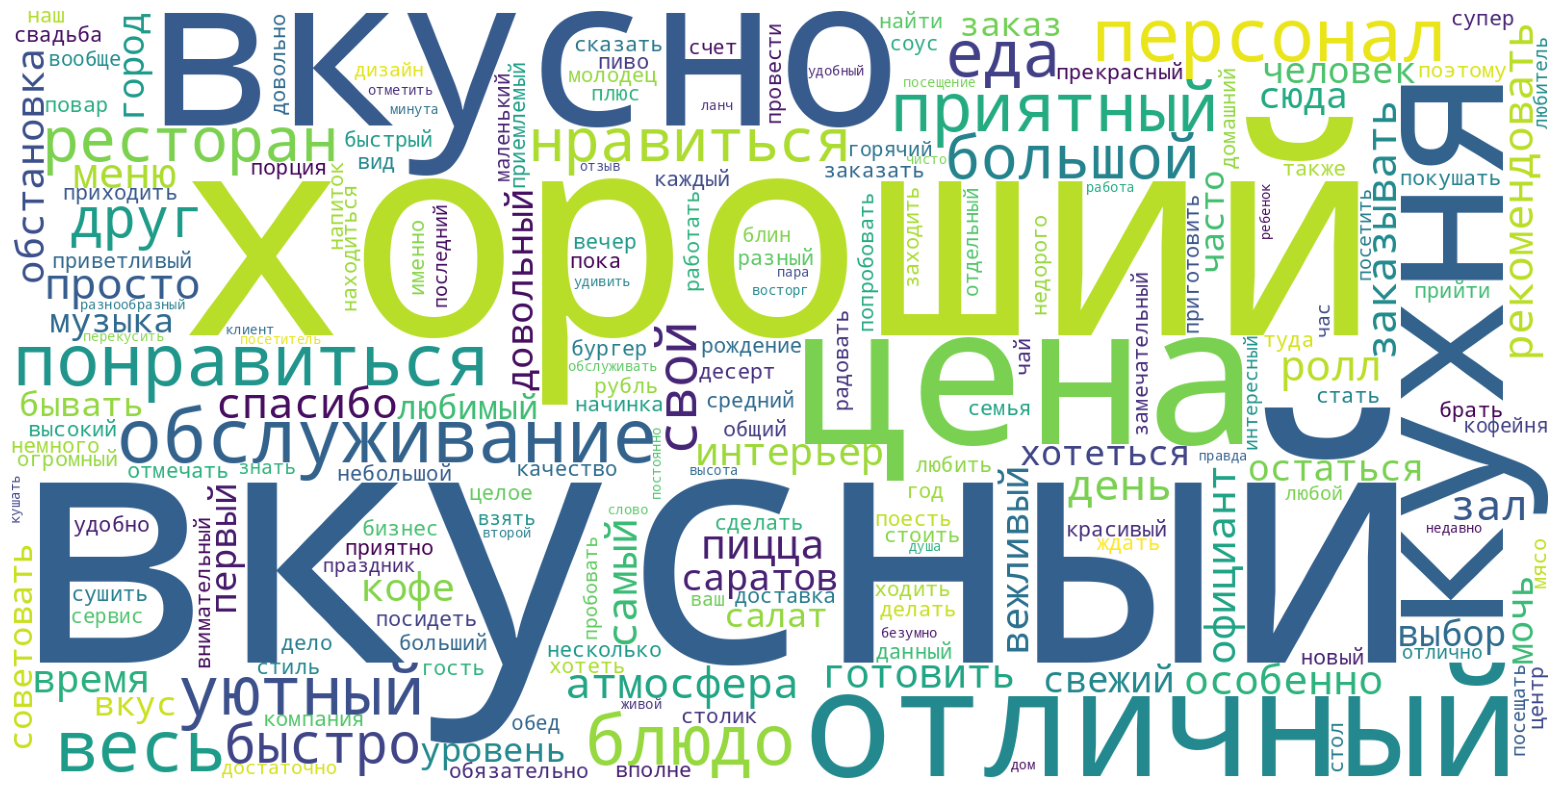

In [ ]:
reviews_5 = reviews_cleared[reviews_cleared.rating == 5].text
word_counts_5 = Counter(chain.from_iterable(review.split() for review in reviews_5))
cloud_5 = WordCloud(
    width=1600, height=800, random_state=0, background_color="white", collocations=False
).generate_from_frequencies(word_counts_5)
plt.figure(figsize=(20, 10))
plt.axis("off")
plt.imshow(cloud_5);

Чаще всего в положительных отзывах встречаются слова: «вкусный», «хороший», «отличный», «приятный» и «уютный».

Подсчёт частоты появления слов в отзывах с оценкой 4 и генерация изображения облака слов.

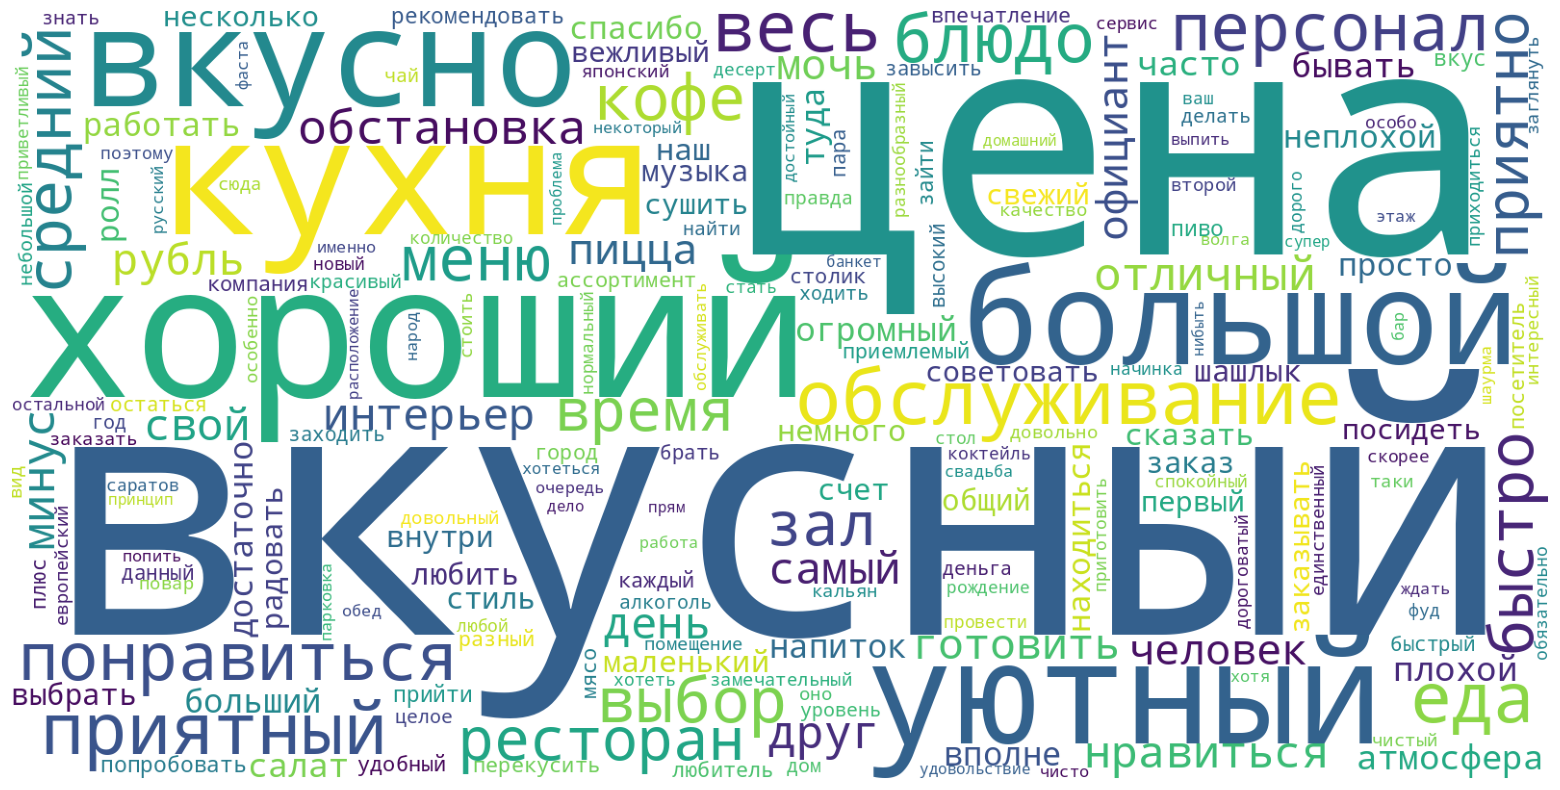

In [ ]:
reviews_4 = reviews_cleared[reviews_cleared.rating == 4].text
word_counts_4 = Counter(chain.from_iterable(review.split() for review in reviews_4))
cloud_4 = WordCloud(
    width=1600, height=800, random_state=0, background_color="white", collocations=False
).generate_from_frequencies(word_counts_4)
plt.figure(figsize=(20, 10))
plt.axis("off")
plt.imshow(cloud_4);

Слово «отличный» стало встречаться заметно реже, а слова «уютный» и «цена» наоборот намного чаще.

Подсчёт частоты появления слов в отзывах с оценкой 3 и генерация изображения облака слов.

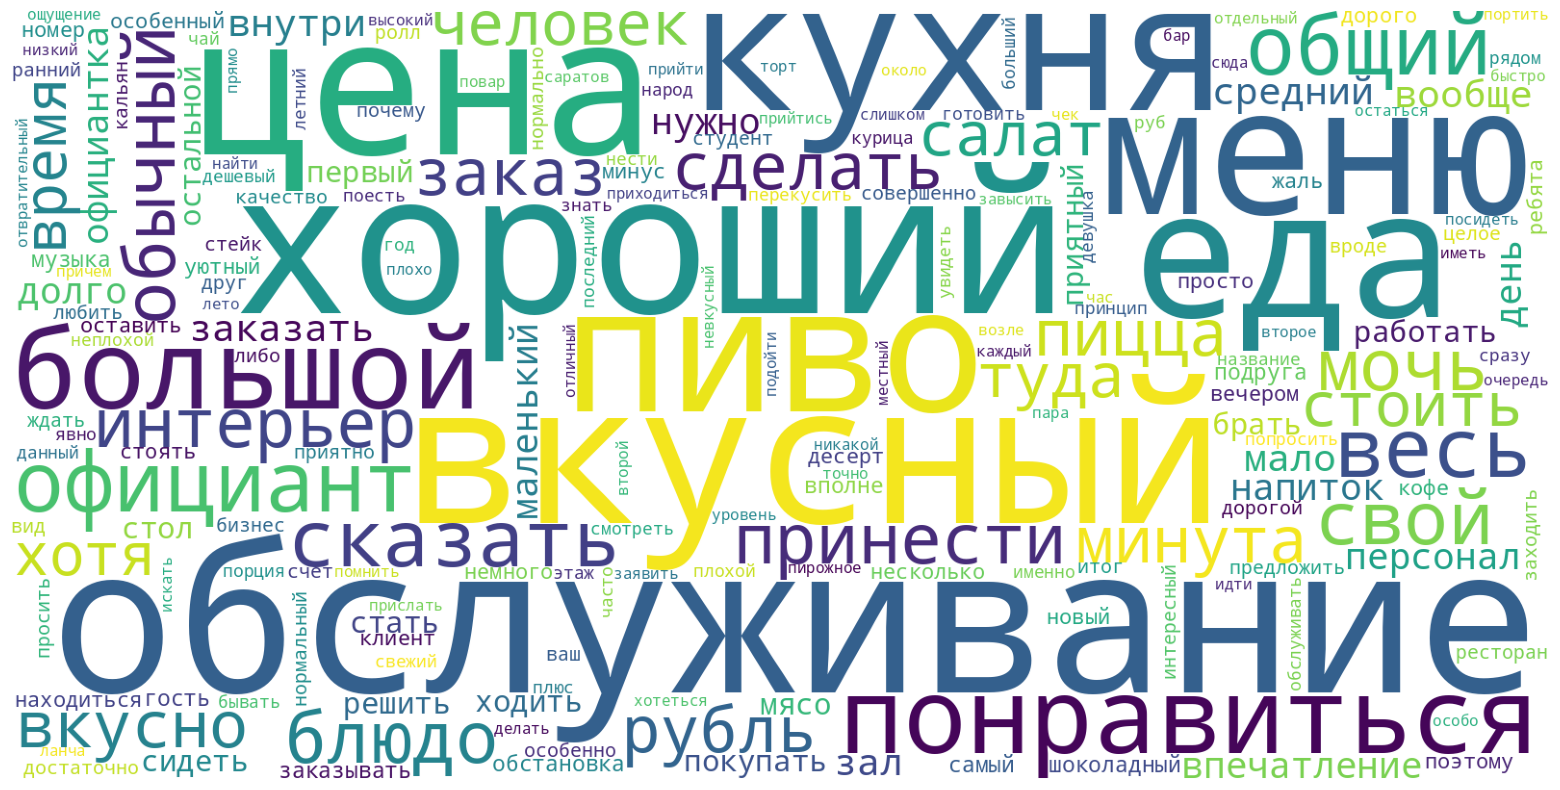

In [ ]:
reviews_3 = reviews_cleared[reviews_cleared.rating == 3].text
word_counts_3 = Counter(chain.from_iterable(review.split() for review in reviews_3))
cloud_3 = WordCloud(
    width=1600, height=800, random_state=0, background_color="white", collocations=False
).generate_from_frequencies(word_counts_3)
plt.figure(figsize=(20, 10))
plt.axis("off")
plt.imshow(cloud_3);

Слово «вкусный» стало встречаться заметно реже. Также, помимо слов «кухня» и «цена», частыми стали «обслуживание», «меню», «еда» и «пиво».

Подсчёт частоты появления слов в отзывах с оценкой 2 и генерация изображения облака слов.

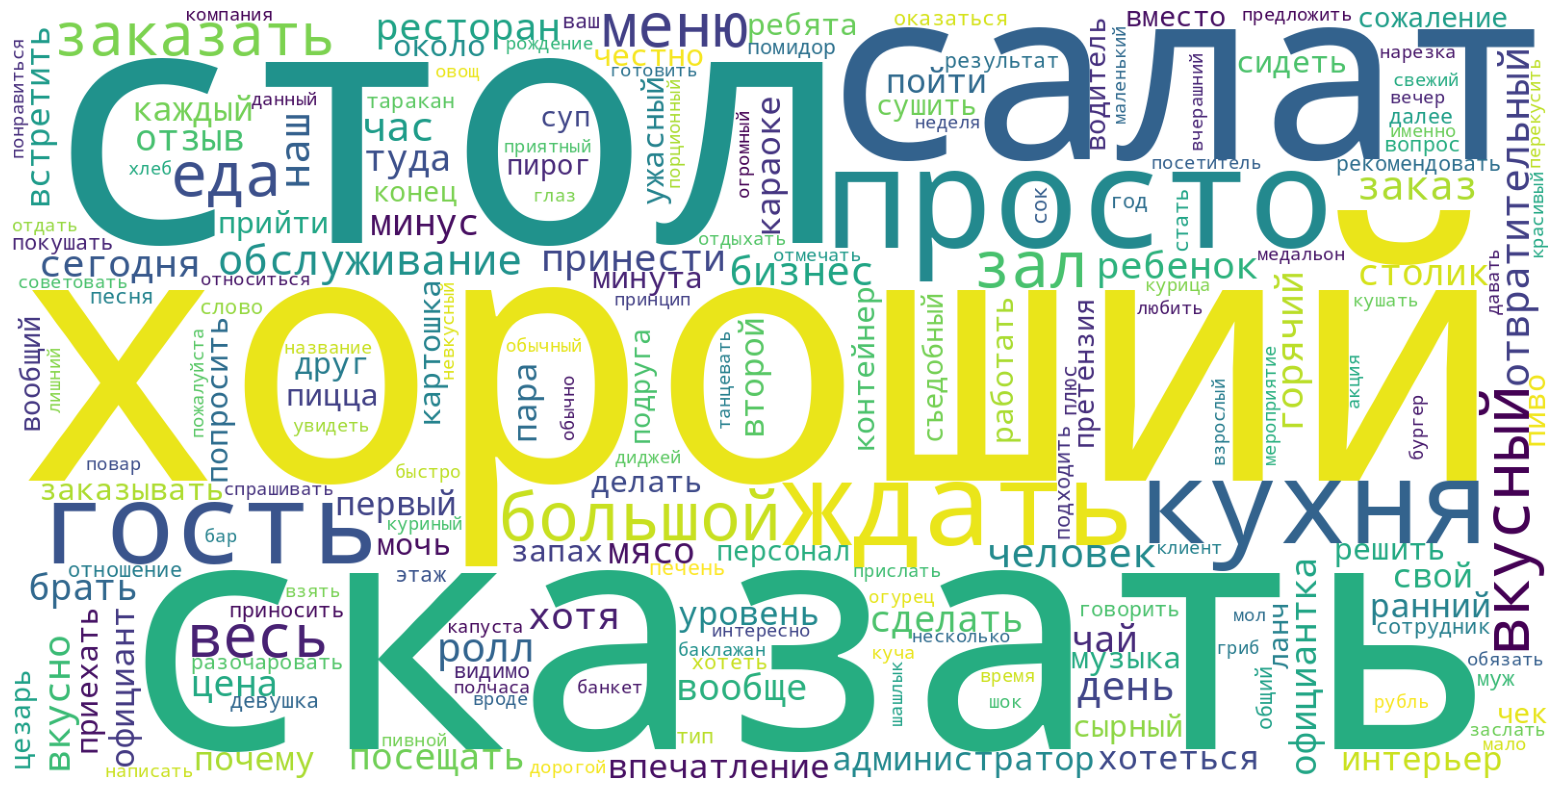

In [ ]:
reviews_2 = reviews_cleared[reviews_cleared.rating == 2].text
word_counts_2 = Counter(chain.from_iterable(review.split() for review in reviews_2))
cloud_2 = WordCloud(
    width=1600, height=800, random_state=0, background_color="white", collocations=False
).generate_from_frequencies(word_counts_2)
plt.figure(figsize=(20, 10))
plt.axis("off")
plt.imshow(cloud_2);

Из «хороших» слов осталось только слово «хороший». Частыми стали слова: «сказать», «стол», «салат», «просто» и «ждать».

Подсчёт частоты появления слов в отзывах с оценкой 1 и генерация изображения облака слов.

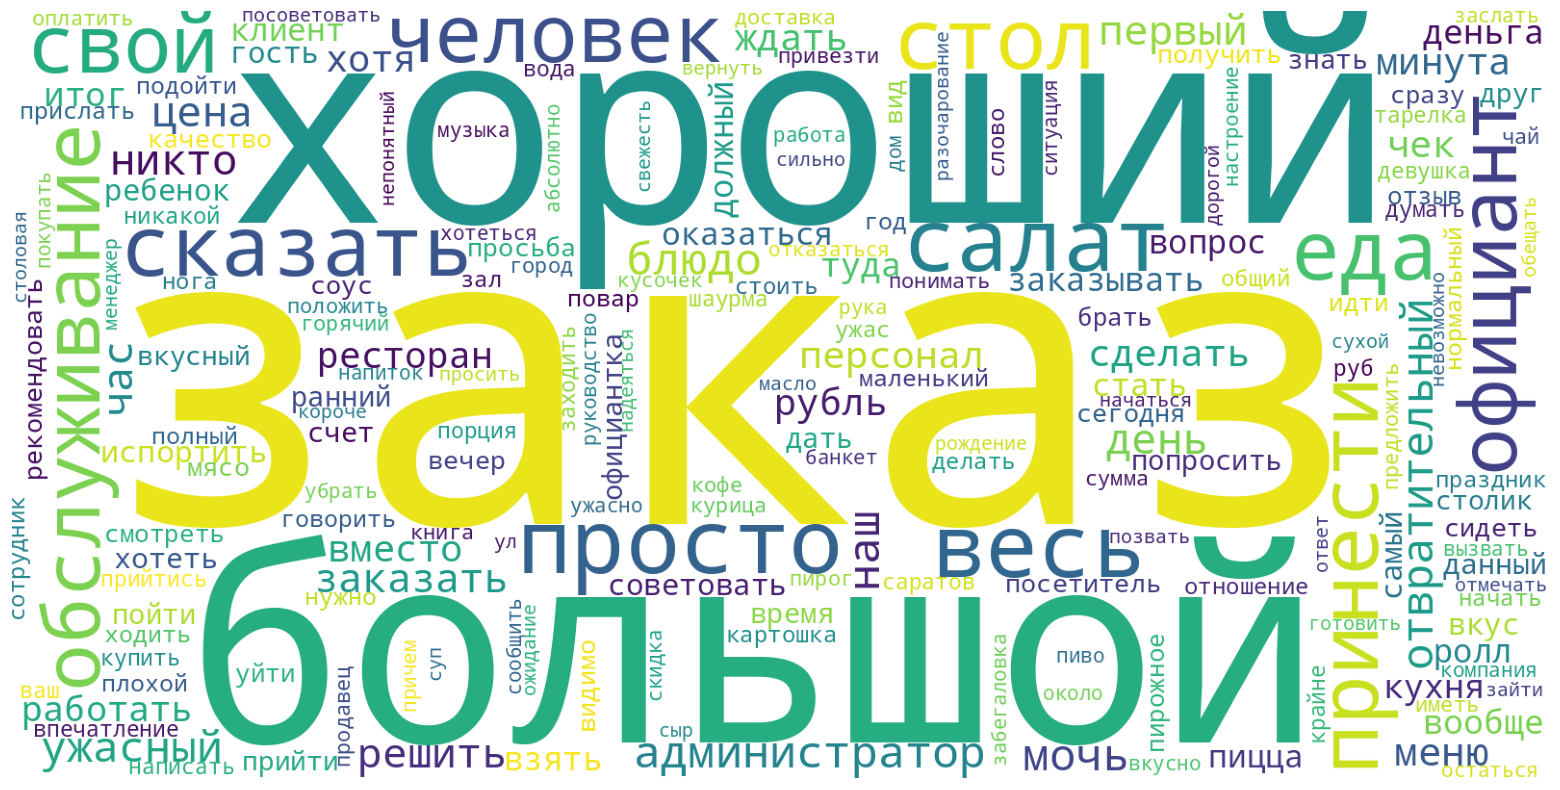

In [ ]:
reviews_1 = reviews_cleared[reviews_cleared.rating == 1].text
word_counts_1 = Counter(chain.from_iterable(review.split() for review in reviews_1))
cloud_1 = WordCloud(
    width=1600, height=800, random_state=0, background_color="white", collocations=False
).generate_from_frequencies(word_counts_1)
plt.figure(figsize=(20, 10))
plt.axis("off")
plt.imshow(cloud_1);

В самых плохих отзывах одним из самых частых слов всё ещё остаётся «хороший». Также, часто встречаются слова «заказ» и «большой». Слова «отвратительный» и «ужасный» присутствуют в отзывах, но в целом встречаются нечасто.